# HDB Rental Main Dataset

### Import dependencies

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

data_dir = "../data"

## Section 1: Preprocessing

In [2]:
train_df = pd.read_csv(f"{data_dir}/train.csv")
train_df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800
...,...,...,...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.0,yes,1985,0.0,2500
149996,2025-03,queenstown,79,dawson road,5-room,improved,107.0,yes,2020,0.0,5300
149997,2025-03,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.0,yes,1971,0.0,2650
149998,2025-03,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.0,yes,2001,0.0,3300


### 1.1 Dropping FURNISHED and FEE
Drop constant columns `FURNISHED` and `FEE`.

In [3]:
train_df.drop(columns=["FURNISHED", "FEE"], inplace=True)
train_df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,2012,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,2001,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,1976,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,2010,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,2001,1800
...,...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220,bukit batok east avenue 3,3-room,new generation,67.0,1985,2500
149996,2025-03,queenstown,79,dawson road,5-room,improved,107.0,2020,5300
149997,2025-03,toa payoh,17,lorong 7 toa payoh,3-room,improved,67.0,1971,2650
149998,2025-03,sembawang,360a,Admiralty Drive,4-room,premium apartment,94.0,2001,3300


### 1.2 Normalizing STREET

Setting `STREET` names all to lowercase.

In [4]:
# Normalize to lowercase
train_df['STREET'] = train_df['STREET'].str.lower()

In [5]:
train_df['STREET'].value_counts()

STREET
ang mo kio avenue 3      2014
ang mo kio avenue 10     1889
yishun ring road         1888
bedok reservoir road     1508
lorong 1 toa payoh       1229
                         ... 
margaret drive              3
yishun street 44            2
ang mo kio street 23        2
yishun street 42            2
bukit batok street 41       2
Name: count, Length: 576, dtype: int64

### 1.3 Concatenating BLOCK and STREET

The `BLOCK` feature is quite useless without the `STREET`, so let us combine them into a single feature since they are inseparable. We create a new feature for this called `BLOCK_STREET`. Then, we can drop `BLOCK` and `STREET`.

In [6]:
train_df.insert(loc=2, column='BLOCK_STREET', value=train_df["BLOCK"] + " " + train_df["STREET"])

train_df.drop(columns=["BLOCK", "STREET"], inplace=True)
train_df

,RENT_APPROVAL_DATE,TOWN,BLOCK_STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,MONTHLY_RENT
0,2021-01,punggol,604a punggol road,4 room,model a,93.0,2012,1800
1,2021-01,sengkang,290c compassvale crescent,5 room,improved,110.0,2001,2000
2,2021-01,queenstown,5 ghim moh road,3 room,improved,65.0,1976,2000
3,2021-01,sengkang,436b fernvale road,4 room,model a,96.0,2010,1400
4,2021-01,sembawang,467b admiralty drive,4 room,premium apartment,102.0,2001,1800
...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220 bukit batok east avenue 3,3-room,new generation,67.0,1985,2500
149996,2025-03,queenstown,79 dawson road,5-room,improved,107.0,2020,5300
149997,2025-03,toa payoh,17 lorong 7 toa payoh,3-room,improved,67.0,1971,2650
149998,2025-03,sembawang,360a admiralty drive,4-room,premium apartment,94.0,2001,3300


### 1.4 Adding FLAT_AGE

`RENT_APPROVAL_DATE` and `LEASE_COMMENCE_DATE` are not very useful for regression, so we will add a new `FLAT_AGE` feature which is simply their difference in years.

In [7]:
train_df["RENT_APPROVAL_YEAR"] = train_df["RENT_APPROVAL_DATE"].str[:4].astype(int)
train_df.insert(loc=6, column='FLAT_AGE', value=train_df["RENT_APPROVAL_YEAR"] - train_df["LEASE_COMMENCE_DATE"])

train_df.drop(columns=["RENT_APPROVAL_YEAR", "LEASE_COMMENCE_DATE"], inplace=True)
train_df

,RENT_APPROVAL_DATE,TOWN,BLOCK_STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,2021-01,punggol,604a punggol road,4 room,model a,93.0,9,1800
1,2021-01,sengkang,290c compassvale crescent,5 room,improved,110.0,20,2000
2,2021-01,queenstown,5 ghim moh road,3 room,improved,65.0,45,2000
3,2021-01,sengkang,436b fernvale road,4 room,model a,96.0,11,1400
4,2021-01,sembawang,467b admiralty drive,4 room,premium apartment,102.0,20,1800
...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220 bukit batok east avenue 3,3-room,new generation,67.0,40,2500
149996,2025-03,queenstown,79 dawson road,5-room,improved,107.0,5,5300
149997,2025-03,toa payoh,17 lorong 7 toa payoh,3-room,improved,67.0,54,2650
149998,2025-03,sembawang,360a admiralty drive,4-room,premium apartment,94.0,24,3300


### 1.5 Integer Encoding FLAT_TYPE

Standardize inconsistent hyphenation of the values (i.e., `4 room` to `4-room`). Then, to make the features better suited for regression, we perform integer encoding (i.e., `executive` = `6`, `5-room` = `5`, etc.).

In [8]:
train_df["FLAT_TYPE"].value_counts()

FLAT_TYPE
4-room       40688
3-room       36932
5-room       26215
4 room       13391
3 room       12092
5 room        9308
executive     8234
2-room        2566
2 room         532
1-room          34
1 room           8
Name: count, dtype: int64

In [9]:
# Standardize hyphenation
train_df["FLAT_TYPE"] = train_df["FLAT_TYPE"].str.replace(" room", "-room")

In [10]:
# Integer encoding
flat_type_encoding = {
    "executive": 6,
    "5-room": 5,
    "4-room": 4,
    "3-room": 3,
    "2-room": 2,
    "1-room": 1
}

train_df["FLAT_TYPE"] = train_df["FLAT_TYPE"].map(flat_type_encoding)

In [11]:
train_df["FLAT_TYPE"].value_counts()

FLAT_TYPE
4    54079
3    49024
5    35523
6     8234
2     3098
1       42
Name: count, dtype: int64

### 1.6 FLAT_TYPE vs. FLOOR_AREA_SQM

Based on the correlation matrix below, `FLAT_TYPE` and `FLOOR_AREA_SQM` have 0.95 correlation with each other which is very high, and they correlate with `MONTHLY_RENT` by 0.34 and 0.33, respectively. We could probably drop one of them since keeping both is redundant. To determine which to drop, we fit multiple models with varying configurations of the features.

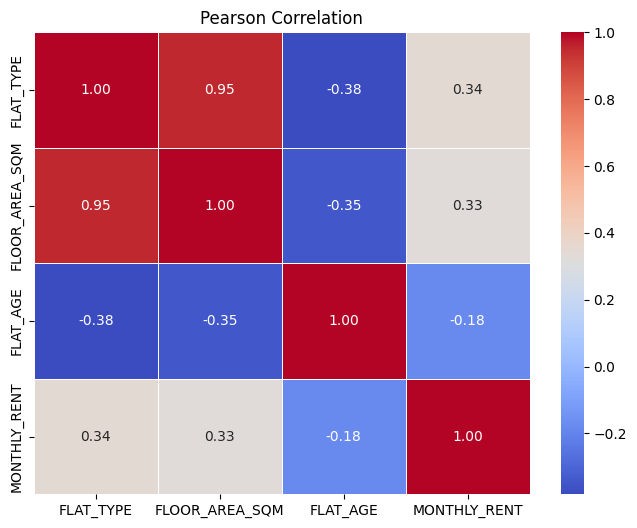

In [12]:
matrix = train_df[['FLAT_TYPE', 'FLOOR_AREA_SQM', 'FLAT_AGE', 'MONTHLY_RENT']].corr()
plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Pearson Correlation")
plt.show()

For testing, let us fit three simple linear regression models: (1) with `FLAT_TYPE`, (2) with `FLOOR_AREA_AQM`, and (3) with both features. Among the three configurations, the model with only `FLAT_TYPE` is consistently the best (lowest MAE and R^2). Therefore, it is reasonable to drop `FLOOR_AREA_SQM` and keep only `FLAT_TYPE`.

In [13]:
ablation_features = [
    ["FLAT_TYPE"],                      # FLAT_TYPE
    ["FLOOR_AREA_SQM"],                 # FLOOR_AREA_SQM
    ["FLAT_TYPE", "FLOOR_AREA_SQM"]     # both
]

for ablation in ablation_features:
    data = train_df.copy()

    features = ablation + ["FLAT_AGE"]
    data = data[features + ["MONTHLY_RENT", "RENT_APPROVAL_DATE"]]
    data["RENT_APPROVAL_DATE"] = pd.to_datetime(data["RENT_APPROVAL_DATE"], format="%Y-%m")
    data = data.sort_values("RENT_APPROVAL_DATE")

    # First 80% for training, last 20% for testing (chronological)
    cutoff_date = data["RENT_APPROVAL_DATE"].iloc[int(len(data) * 0.8)]
    train = data[data["RENT_APPROVAL_DATE"] < cutoff_date]
    test = data[data["RENT_APPROVAL_DATE"] >= cutoff_date]

    X_train = train[features].copy()
    X_test = test[features].copy()
    y_train = train["MONTHLY_RENT"]
    y_test = test["MONTHLY_RENT"]

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("Features: ", features)
    print("Cutoff:", cutoff_date)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("R^2:", r2_score(y_test, predictions))
    print()

Features:  ['FLAT_TYPE', 'FLAT_AGE']
Cutoff: 2024-05-01 00:00:00
MAE: 653.9883822714062
R^2: -0.42249943822099967

Features:  ['FLOOR_AREA_SQM', 'FLAT_AGE']
Cutoff: 2024-05-01 00:00:00
MAE: 657.0337894518511
R^2: -0.439110319384

Features:  ['FLAT_TYPE', 'FLOOR_AREA_SQM', 'FLAT_AGE']
Cutoff: 2024-05-01 00:00:00
MAE: 654.0379926420155
R^2: -0.4224181242687217



### 1.7 FLAT_MODEL Suspicious Values

All flat models look valid, except for a suspicious `2 room` model which seems redundant since this is identical to the `FLAT_TYPE`.

In [22]:
train_df["FLAT_MODEL"].value_counts()

FLAT_MODEL
improved                  44008
model a                   42745
new generation            27380
premium apartment         12312
simplified                 6794
standard                   5903
apartment                  4724
maisonette                 2346
model a2                   1553
dbss                       1090
type s1                     299
2 room                      224
adjoined flat               218
type s2                     160
model a maisonette          140
premium apartment loft       51
premium maisonette           21
terrace                      19
3gen                         12
improved maisonette           1
Name: count, dtype: int64

As expected, all `FLAT_MODEL = 2 room` records are of `FLAT_TYPE = 2`.

In [20]:
train_df[train_df["FLAT_MODEL"] == "2 room"]

,RENT_APPROVAL_DATE,TOWN,BLOCK_STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
65,2021-01,central,9 jalan kukoh,2,2 room,55.0,39,1500
1320,2021-01,bukit merah,127a kim tian road,2,2 room,47.0,8,1800
2282,2021-01,pasir ris,528a pasir ris street 51,2,2 room,47.0,6,1700
6577,2021-03,punggol,256a sumang walk,2,2 room,47.0,5,1600
7372,2021-03,hougang,993a buangkok link,2,2 room,47.0,0,1700
...,...,...,...,...,...,...,...,...
149721,2025-03,bukit merah,127a kim tian road,2,2 room,47.0,12,3000
149737,2025-03,hougang,994b buangkok link,2,2 room,47.0,4,2500
149770,2025-03,yishun,462a yishun avenue 6,2,2 room,38.0,6,2400
149773,2025-03,bukit batok,436a bukit batok west avenue 5,2,2 room,47.0,5,2500


Comparing it with other records with `FLAT_TYPE = 2`, we may note that the `FLAT_MODEL` values can be more varied and descriptive.

In [33]:
train_df[train_df["FLAT_TYPE"] == 2]

,RENT_APPROVAL_DATE,TOWN,BLOCK_STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
16,2021-01,geylang,32 balam road,2,standard,46.0,48,1600
52,2021-01,toa payoh,54 lorong 5 toa payoh,2,standard,43.0,54,1000
65,2021-01,central,9 jalan kukoh,2,2 room,55.0,39,1500
141,2021-01,woodlands,780f woodlands crescent,2,model a,47.0,6,1000
174,2021-01,bedok,541 bedok north street 3,2,improved,45.0,36,1500
...,...,...,...,...,...,...,...,...
149743,2025-03,bukit merah,48 lower delta road,2,standard,42.0,55,2200
149770,2025-03,yishun,462a yishun avenue 6,2,2 room,38.0,6,2400
149773,2025-03,bukit batok,436a bukit batok west avenue 5,2,2 room,47.0,5,2500
149789,2025-03,jurong west,150a corporation drive,2,2 room,47.0,6,2150


If we consider `2 room` values for `FLAT_MODEL` as an error, we can attempt a reconstruction. One approach is to determine the `FLAT_MODEL` of other records at similar `BLOCK_STREET` and `FLAT_TYPE` combinations. However, the issue with this approach is that records with `2 room` values appear to have all their records completely affected for their `BLOCK_STREET` and `FLAT_TYPE` combinations. See below as an example.

In [37]:
train_df[train_df["BLOCK_STREET"] == "9 jalan kukoh"].head(20)

,RENT_APPROVAL_DATE,TOWN,BLOCK_STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
65,2021-01,central,9 jalan kukoh,2,2 room,55.0,39,1500
24357,2021-08,central,9 jalan kukoh,2,2 room,55.0,39,1550
28154,2021-09,central,9 jalan kukoh,3,improved,66.0,39,1600
29417,2021-10,central,9 jalan kukoh,2,2 room,55.0,39,1650
31912,2021-11,central,9 jalan kukoh,2,2 room,55.0,39,1900
35377,2021-12,central,9 jalan kukoh,2,2 room,55.0,39,1200
36185,2021-12,central,9 jalan kukoh,2,2 room,55.0,39,1400
44608,2022-03,central,9 jalan kukoh,3,improved,66.0,40,2200
44975,2022-03,central,9 jalan kukoh,3,improved,66.0,40,2500
45578,2022-03,central,9 jalan kukoh,2,2 room,55.0,40,1500


Consequently, there does not seem to be a reliable way to fix or reconstruct the real value for `FLAT_MODEL`. It does not seem to be worth dropping the records either just because of this minor issue, so the verdict is to leave the `2 room` records as is.

Let us inspect the main dataset after preprocessing.

In [14]:
train_df

,RENT_APPROVAL_DATE,TOWN,BLOCK_STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FLAT_AGE,MONTHLY_RENT
0,2021-01,punggol,604a punggol road,4,model a,93.0,9,1800
1,2021-01,sengkang,290c compassvale crescent,5,improved,110.0,20,2000
2,2021-01,queenstown,5 ghim moh road,3,improved,65.0,45,2000
3,2021-01,sengkang,436b fernvale road,4,model a,96.0,11,1400
4,2021-01,sembawang,467b admiralty drive,4,premium apartment,102.0,20,1800
...,...,...,...,...,...,...,...,...
149995,2025-03,bukit batok,220 bukit batok east avenue 3,3,new generation,67.0,40,2500
149996,2025-03,queenstown,79 dawson road,5,improved,107.0,5,5300
149997,2025-03,toa payoh,17 lorong 7 toa payoh,3,improved,67.0,54,2650
149998,2025-03,sembawang,360a admiralty drive,4,premium apartment,94.0,24,3300


## Test

In [ ]:
# test_df = pd.read_csv(f"{data_dir}/test.csv")
# test_df

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE
0,2025-03,kallang/whampoa,74,Whampoa Drive,3-room,improved,66.0,yes,1981,0.0
1,2025-03,bukit timah,6,farrer road,4-room,improved,91.0,yes,1974,0.0
2,2025-03,pasir ris,755,Pasir Ris Street 71,4-room,model a,105.0,yes,1996,0.0
3,2025-03,punggol,299,punggol central,4-room,premium apartment,94.0,yes,2003,0.0
4,2025-03,tampines,869a,tampines avenue 8,4-room,model a,92.0,yes,2015,0.0
...,...,...,...,...,...,...,...,...,...,...
49995,2026-07,bukit batok,138,bukit batok west avenue 6,3-room,new generation,68.0,yes,1984,0.0
49996,2026-07,queenstown,88,dawson road,4-room,premium apartment,83.0,yes,2016,0.0
49997,2026-07,toa payoh,235,lorong 8 toa payoh,3-room,improved,76.0,yes,1976,0.0
49998,2026-07,bukit panjang,613,Bukit Panjang Ring Road,4-room,model a,90.0,yes,2002,0.0
